In [57]:
import pandas as pd
import numpy as np

from lifelines import KaplanMeierFitter
import matplotlib.pyplot as plt


from lifelines import AalenJohansenFitter
import matplotlib.pyplot as plt

In [58]:

def simulate_competing_risks(
    n_samples=10000,
    seed=None,
    baseline_hazard_event1=0.01,
    baseline_hazard_event2=0.05,
    censoring_rate=0.01
):
    """
    Synthetic competing-risks data.

    Event coding:
        0 = Censored
        1 = Event 1
        2 = Event 2
    """

    rng = np.random.default_rng(seed)

    # Continuous covariates
    X_cont = rng.normal(0, 1, size=(n_samples, 6))

    # Binary covariates
    X_bin = rng.binomial(1, 0.5, size=(n_samples, 6))

    X = np.hstack([X_cont, X_bin])

    feature_names = [f"x{i}" for i in range(1, 13)]

    # True coefficients
    beta_event1 = np.array([
        1.20, #x1
       -0.95, #x2
        0.00, #x3
        0.00, #x4
        0.60, #x5
       -0.40, #x6
        1.80, #x7
       -1.50, #x8
        0.00, #x9
        0.00, #x10
        0.90, #x11
       -0.70  #x12
    ])

    
    beta_event2 = np.array([
        0.00, #x1
        0.00, #x2
        1.10, #x3
       -0.80, #x4
        0.50, #x5
       -0.30, #x6
        0.00, #x7
        0.00, #x8
        1.60, #x9
       -1.20, #x10
        0.75, #x11
       -0.50  #x12
    ])

    # Linear predictors
    eta1 = X @ beta_event1
    eta2 = X @ beta_event2

    # Cause-specific hazards
    lambda1 = baseline_hazard_event1 * np.exp(eta1)
    lambda2 = baseline_hazard_event2 * np.exp(eta2)

    # Overall hazard
    total_hazard = lambda1 + lambda2

    # Event times
    event_time = -np.log(rng.uniform(size=n_samples)) / total_hazard

    # Event type
    prob_event1 = lambda1 / total_hazard
    event_type = np.where(
        rng.uniform(size=n_samples) < prob_event1,
        1,
        2
    )

    # Independent censoring
    censor_time = rng.exponential(
        scale=1 / censoring_rate,
        size=n_samples
    )

    # Observed outcome
    observed_time = np.minimum(event_time, censor_time)

    event = np.where(
        event_time <= censor_time,
        event_type,
        0
    )

    # DataFrame
    df = pd.DataFrame(X, columns=feature_names)

    df["time"] = observed_time
    df["event"] = event

    # Optional: retain true risk scores
    df["true_lp_event1"] = eta1
    df["true_lp_event2"] = eta2

    return df

### Note: Remember we add the true lp event.


Check whether the model recovers the true risk ordering

If your model is working correctly, its predicted risk score should be highly correlated with the true linear predictor.

### Note: model needs to be upadted for real world data

In [59]:
df_synthetic = simulate_competing_risks(n_samples=6000, seed=42, baseline_hazard_event1=0.01, baseline_hazard_event2=0.05, censoring_rate=0.01)



df_synthetic.head()

,x1,x2,x3,x4,x5,x6,x7,x8,x9,x10,x11,x12,time,event,true_lp_event1,true_lp_event2
0,0.304717,-1.039984,0.750451,0.940565,-1.951035,-1.302180,1.0,1.0,0.0,1.0,1.0,0.0,15.084821,1,1.903896,-0.961819
1,0.127840,-0.316243,-0.016801,-0.853044,0.879398,0.777792,1.0,1.0,0.0,1.0,0.0,0.0,10.759874,2,0.970361,-0.329685
2,0.066031,1.127241,0.467509,-0.859292,0.368751,-0.958883,0.0,1.0,1.0,1.0,0.0,0.0,14.434709,2,-1.886839,2.073734
3,0.878450,-0.049926,-0.184862,-0.680930,1.222541,-0.154529,1.0,1.0,0.0,0.0,1.0,1.0,1.045714,2,2.396907,1.249025
4,-0.428328,-0.352134,0.532309,0.365444,0.412733,0.430821,0.0,1.0,0.0,1.0,0.0,1.0,128.513629,2,-2.304155,-1.329695


verify that the simulation behaves as expected if the said lp of the event is higer then the rest

In [60]:
df_synthetic.groupby("event")["true_lp_event1"].mean()

event
0   -1.031232
1    2.060794
2   -0.174486
Name: true_lp_event1, dtype: float64

In [61]:
df_synthetic.groupby("event")["true_lp_event2"].mean()

event
0   -1.383771
1   -0.501286
2    1.032139
Name: true_lp_event2, dtype: float64

## Plots to confirm synthetic data is correct 

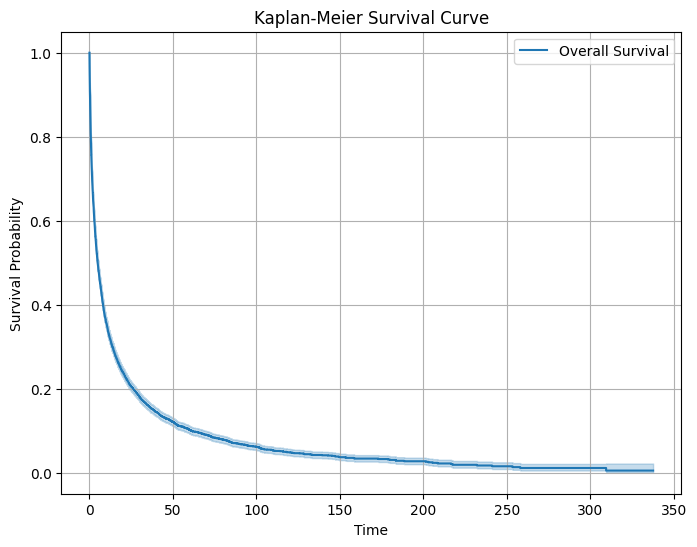

In [62]:
# kaplan meier curve


kmf = KaplanMeierFitter()

overall_event = (df_synthetic["event"] != 0).astype(int)

kmf.fit(
    durations=df_synthetic["time"],
    event_observed=overall_event,
    label="Overall Survival"
)

plt.figure(figsize=(8,6))
kmf.plot_survival_function()
plt.title("Kaplan-Meier Survival Curve")
plt.xlabel("Time")
plt.ylabel("Survival Probability")
plt.grid(True)
plt.show()



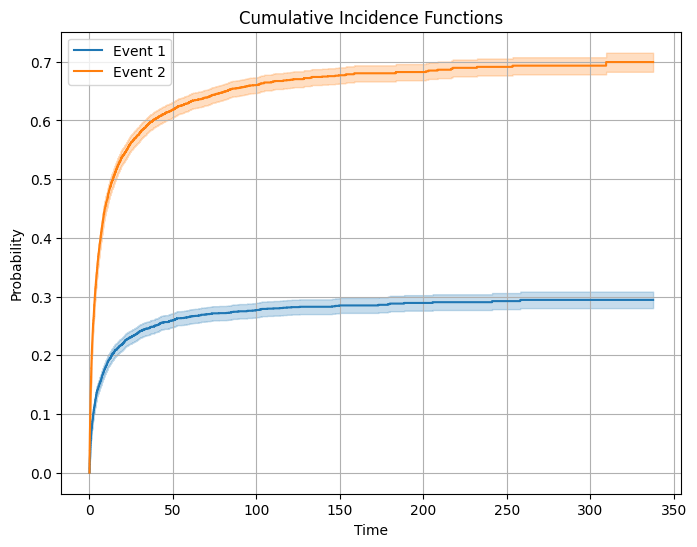

In [63]:


plt.figure(figsize=(8,6))

ajf1 = AalenJohansenFitter()
ajf1.fit(
    durations=df_synthetic["time"],
    event_observed=df_synthetic["event"],
    event_of_interest=1
)

ajf1.plot(label="Event 1")

ajf2 = AalenJohansenFitter()
ajf2.fit(
    durations=df_synthetic["time"],
    event_observed=df_synthetic["event"],
    event_of_interest=2
)

ajf2.plot(label="Event 2")

plt.title("Cumulative Incidence Functions")
plt.xlabel("Time")
plt.ylabel("Probability")
plt.grid(True)
plt.legend()
plt.show()

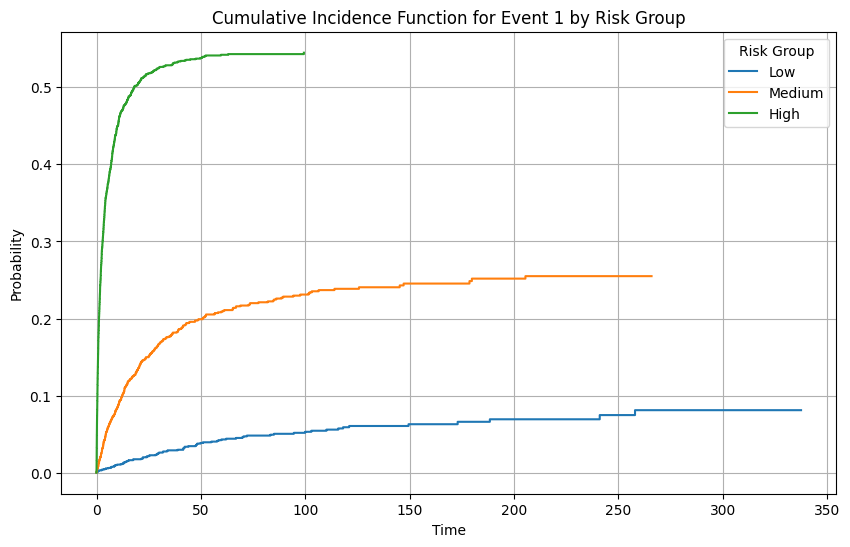

In [64]:
plt.figure(figsize=(10,6))

# Group observations by the true risk score for event 1
# so that we can plot CIF curves separately for each group.
df_synthetic["risk_group"] = pd.qcut(
    df_synthetic["true_lp_event1"],
    q=3,
    labels=["Low","Medium","High"]
)

for group in ["Low", "Medium", "High"]:
    subgroup = df_synthetic[df_synthetic["risk_group"] == group]
    ajf1 = AalenJohansenFitter()
    ajf1.fit(
        durations=subgroup["time"],
        event_observed=subgroup["event"],
        event_of_interest=1,
        label=group
    )
    ajf1.plot(ci_show=False)

plt.title("Cumulative Incidence Function for Event 1 by Risk Group")
plt.xlabel("Time")
plt.ylabel("Probability")
plt.grid(True)
plt.legend(title="Risk Group")
plt.show()



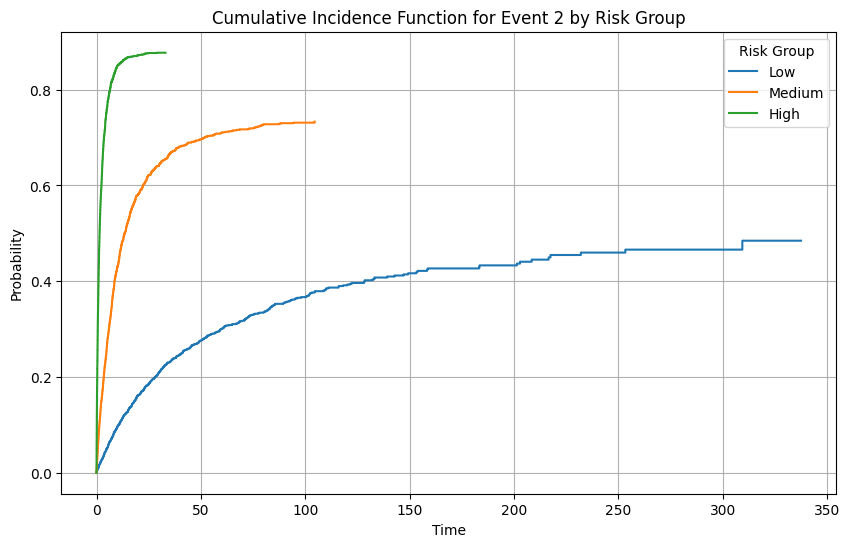

In [65]:
# Group observations by the true risk score for event 1
# so that we can plot CIF curves separately for each group.
df_synthetic["risk_group"] = pd.qcut(
    df_synthetic["true_lp_event2"],
    q=3,
    labels=["Low","Medium","High"]
)

plt.figure(figsize=(10,6))
for group in ["Low", "Medium", "High"]:
    subgroup = df_synthetic[df_synthetic["risk_group"] == group]
    ajf2 = AalenJohansenFitter()
    ajf2.fit(
        durations=subgroup["time"],
        event_observed=subgroup["event"],
        event_of_interest=2,
        label=group
    )
    ajf2.plot(ci_show=False)

plt.title("Cumulative Incidence Function for Event 2 by Risk Group")
plt.xlabel("Time")
plt.ylabel("Probability")
plt.grid(True)
plt.legend(title="Risk Group")
plt.show()